# 第7章：组合构建——解析解、NCO与skfolio

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from time import perf_counter
from notebook_common import load_data, setup_notebook, timed, quiet, matrix_stats

SEED = 42
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 统一风险输入与异常记录
[原代码](Machine_Learning_for_Asset_Managers/ch7_portfolio_construction.py)的 `allocate_cvo` 没有非负约束；
有均值时按 `mu.T @ w` 归一化，不保证权重和为1。本章受控对照仅比较最小方差。
输入统一为经验协方差，不加入去市场成分。原求逆失败、病态解或优化失败均记录，
不静默使用伪逆、不删资产。关闭正定修复的受控模型与默认修复的实用模型分开标注。
部分基金的单日方差极小，默认求解精度可能掩盖真实最优解；因此保留默认精度GMV作诊断，
主对照和第8章统一使用 `scale_objective=1e4`、CLARABEL三项容差 `1e-12`。
乘以正常数仅改变数值尺度，不改变数学最优解；没有重标度收益、替换协方差或增加策略试验。

In [2]:
from Machine_Learning_for_Asset_Managers import ch7_portfolio_construction as original
from Machine_Learning_for_Asset_Managers import ch4_optimal_clustering as original_cluster
from skfolio.optimization import MeanRisk, NestedClustersOptimization, HierarchicalRiskParity
from skfolio.moments import EmpiricalCovariance
from skfolio.prior import EmpiricalPrior
from skfolio.model_selection import WalkForward
from skfolio.distance import PearsonDistance
from sklearn.base import BaseEstimator, ClusterMixin
cov = X_train.cov().to_numpy()
display(pd.DataFrame([matrix_stats(cov)], index=['经验协方差']))
print('原allocate_cvo允许负权重：', original.allocate_cvo(np.array([[1., 1.5], [1.5, 4.]])).ravel())
print('原allocate_cvo有均值时权重和：', original.allocate_cvo(np.eye(2), np.array([[.1], [.2]])).sum())
weights, failures, run_times, fitted_models = {}, {}, {}, {}
SOLVER_OPTIONS = {'scale_objective': 1e4, 'save_problem': True, 'solver_params':
                  {'tol_gap_abs': 1e-12, 'tol_gap_rel': 1e-12, 'tol_feas': 1e-12}}

def attempt(name, function):
    start = perf_counter()
    print('开始：', name, flush=True)
    try:
        value = function()
        if hasattr(value, 'weights_'):
            fitted_models[name] = value
            value = value.weights_
        value = np.asarray(value, dtype=float).ravel()
        if value.shape != (len(assets),) or not np.isfinite(value).all():
            raise ValueError('权重维度错误或含非有限值')
        if not np.isclose(value.sum(), 1, atol=1e-5):
            raise ValueError(f'权重和不为1：{value.sum()}')
        weights[name] = value
        model = fitted_models.get(name)
        if model is not None and getattr(model, 'problem_', None) is not None:
            print('求解状态：', model.problem_.status)
    except Exception as exc:
        failures[name] = f'{type(exc).__name__}: {exc}'
        print('失败（不回退）：', failures[name])
    finally:
        run_times[name] = perf_counter()-start
        print(f'结束：{name}，{run_times[name]:.2f}秒', flush=True)

def unconstrained():
    return MeanRisk(min_weights=None, max_weights=None, **SOLVER_OPTIONS,
                    prior_estimator=EmpiricalPrior(covariance_estimator=EmpiricalCovariance(nearest=False)))

attempt('原解析GMV', lambda: original.minVarPort(cov))
attempt('skfolio无边界GMV（默认精度诊断）', lambda: MeanRisk(min_weights=None, max_weights=None,
        prior_estimator=EmpiricalPrior(covariance_estimator=EmpiricalCovariance(nearest=False))).fit(X_train))
attempt('skfolio无权重边界GMV', lambda: unconstrained().fit(X_train))
attempt('skfolio long-only GMV（默认修复）', lambda: MeanRisk(**SOLVER_OPTIONS).fit(X_train))
if '原解析GMV' in weights and 'skfolio无权重边界GMV' in weights:
    print('GMV受控精度最大权重差：', np.max(np.abs(weights['原解析GMV']-weights['skfolio无权重边界GMV'])))
    if 'skfolio无边界GMV（默认精度诊断）' in weights:
        print('GMV默认精度最大权重差：', np.max(np.abs(weights['原解析GMV']-weights['skfolio无边界GMV（默认精度诊断）'])))
    if data.smoke and np.linalg.cond(cov) < 1e10:
        np.testing.assert_allclose(weights['原解析GMV'], weights['skfolio无权重边界GMV'], atol=1e-5)

,最小特征值,最大特征值,条件数,可Cholesky分解
经验协方差,7.217795e-11,0.063522,8.800756e+08,True


原allocate_cvo允许负权重： [ 1.25 -0.25]
原allocate_cvo有均值时权重和： 5.999999999999999
开始： 原解析GMV


结束：原解析GMV，0.01秒


开始： skfolio无边界GMV（默认精度诊断）


结束：skfolio无边界GMV（默认精度诊断），0.57秒


开始： skfolio无权重边界GMV


求解状态： optimal
结束：skfolio无权重边界GMV，0.65秒


开始： skfolio long-only GMV（默认修复）


求解状态： optimal
结束：skfolio long-only GMV（默认修复），0.88秒


GMV受控精度最大权重差： 5.659181456785234e-11
GMV默认精度最大权重差： 0.3641290208030662


## 2. 原NCO受控复现与相同簇划分的skfolio
原 `optPort_nco` 使用Base聚类而非Top。先调用同一Base函数，再复现原簇内/簇间公式。
唯一兼容调整是浮点权重存储，并暴露分组以便两方共享；不改变模块、不猴子补丁。
原实现不限制做空，skfolio内外层也解除权重边界。`cv="ignore"`仅用于受控比较，不作为推荐回测方式。
层次+前向CV扩展的部分子问题可能报告 `Solution may be inaccurate`，保留原始警告；
即使最终权重通过预算和有限性检查，也不保证各子问题达到指定精度，不把该扩展当成严格等价结果。

In [3]:
MAX_CLUSTERS = min(6 if data.smoke else 20, len(assets)//2)
np.random.seed(SEED)
cluster_result, cluster_seconds = timed('NCO共用ONC Base', lambda: quiet(lambda:
    original_cluster.clusterKMeansBase(X_train.corr().clip(-1, 1), maxNumClusters=MAX_CLUSTERS, n_init=10)))
clusters = cluster_result[1]
shared_labels = pd.Series(-1, index=assets, dtype=int)
for label, members in clusters.items():
    shared_labels.loc[members] = label

class FixedClustering(ClusterMixin, BaseEstimator):
    def __init__(self, labels):
        self.labels = labels
    def fit(self, X, y=None):
        if len(X) != len(self.labels):
            raise ValueError('固定分组与资产顺序不一致')
        self.labels_ = np.asarray(self.labels, dtype=int)
        return self

def original_nco_compatible():
    intra = np.zeros((len(assets), len(clusters)), dtype=float)
    for column, members in enumerate(clusters.values()):
        indices = assets.get_indexer(members)
        intra[indices, column] = original.allocate_cvo(cov[np.ix_(indices, indices)]).ravel()
    reduced_covariance = intra.T @ cov @ intra
    inter = original.allocate_cvo(reduced_covariance).ravel()
    return intra @ inter

attempt('原NCO（浮点兼容复现）', original_nco_compatible)
attempt('skfolio NCO（同簇无CV）', lambda: NestedClustersOptimization(
    inner_estimator=unconstrained(), outer_estimator=unconstrained(),
    clustering_estimator=FixedClustering(tuple(shared_labels)), cv='ignore', n_jobs=1).fit(X_train))
if '原NCO（浮点兼容复现）' in weights and 'skfolio NCO（同簇无CV）' in weights:
    print('同簇NCO最大权重差：', np.max(np.abs(weights['原NCO（浮点兼容复现）']-weights['skfolio NCO（同簇无CV）'])))
attempt('skfolio NCO（层次+前向CV）', lambda: NestedClustersOptimization(
    inner_estimator=MeanRisk(**SOLVER_OPTIONS), outer_estimator=MeanRisk(**SOLVER_OPTIONS),
    cv=WalkForward(train_size=504, test_size=126), n_jobs=1).fit(X_train))
attempt('skfolio HRP', lambda: HierarchicalRiskParity().fit(X_train))
print('共用ONC聚类额外耗时：', cluster_seconds)
print('共用ONC簇规模：', shared_labels.value_counts().sort_index().to_dict())
membership = pd.DataFrame({'共用ONC簇': shared_labels}, index=assets)
for name, model in fitted_models.items():
    if hasattr(model, 'clustering_estimator_'):
        membership[name] = model.clustering_estimator_.labels_
        print(name, '簇规模：', pd.Series(model.clustering_estimator_.labels_).value_counts().sort_index().to_dict())
display(membership)

开始：NCO共用ONC Base


原函数日志共1行，末尾： maxNumClusters20
完成：NCO共用ONC Base，耗时 15.31 秒


开始： 原NCO（浮点兼容复现）


结束：原NCO（浮点兼容复现），0.01秒


开始： skfolio NCO（同簇无CV）


...

结束：skfolio NCO（层次+前向CV），1.15秒


开始： skfolio HRP


结束：skfolio HRP，1.27秒


共用ONC聚类额外耗时： 15.305773700005375
共用ONC簇规模： {0: 406, 1: 82}
skfolio NCO（同簇无CV） 簇规模： {0: 406, 1: 82}
skfolio NCO（层次+前向CV） 簇规模： {0: 66, 1: 40, 2: 167, 3: 34, 4: 181}


,共用ONC簇,skfolio NCO（同簇无CV）,skfolio NCO（层次+前向CV）
159001.SZ,1,1,0
159003.SZ,1,1,0
159005.SZ,1,1,0
159703.SZ,0,0,4
159708.SZ,0,0,2
...,...,...,...
588300.SH,0,0,4
588330.SH,0,0,4
588360.SH,0,0,4
588380.SH,0,0,4


,训练单日方差,测试单日均值,测试单日波动,测试非年化夏普,最大绝对权重,总敞口,绝对权重集中度,负权重数,拟合耗时秒（不含共用聚类）
模型,,,,,,,,,
原解析GMV,6.408591e-11,2.309075e-06,0.000040,0.057538,0.874127,1.198611,0.541878,253,0.009107
skfolio无边界GMV（默认精度诊断）,1.380750e-10,-1.193910e-06,0.000035,-0.034429,1.238256,1.718312,0.536252,239,0.573793
skfolio无权重边界GMV,6.408591e-11,2.309075e-06,0.000040,0.057538,0.874127,1.198611,0.541878,253,0.653870
skfolio long-only GMV（默认修复）,1.338913e-10,2.503520e-07,0.000011,0.022081,0.906344,1.000000,0.828410,0,0.883397
原NCO（浮点兼容复现）,1.149852e-10,5.402755e-06,0.000071,0.076605,0.887825,1.139682,0.617481,228,0.008036
skfolio NCO（同簇无CV）,1.149852e-10,5.402755e-06,0.000071,0.076605,0.887825,1.139682,0.617481,228,0.290816
skfolio NCO（层次+前向CV）,1.350183e-10,3.655553e-07,0.000011,0.032545,0.906354,1.000000,0.828542,0,1.149073
skfolio HRP,1.501411e-10,1.261376e-07,0.000013,0.009746,0.873345,1.000000,0.771106,0,1.266820


Series([], Name: 失败原因（未替换）, dtype: object)

,原解析GMV,skfolio无边界GMV（默认精度诊断）,skfolio无权重边界GMV,skfolio long-only GMV（默认修复）,原NCO（浮点兼容复现）,skfolio NCO（同簇无CV）,skfolio NCO（层次+前向CV）,skfolio HRP
159001.SZ,0.874127,1.238256,0.874127,9.063437e-01,8.878251e-01,8.878251e-01,9.063542e-01,8.733454e-01
159003.SZ,0.105795,-0.217370,0.105795,8.301205e-02,9.631631e-02,9.631631e-02,8.370076e-02,9.065742e-02
159005.SZ,0.005339,-0.009269,0.005339,7.449103e-03,7.501737e-03,7.501737e-03,7.503791e-03,6.257066e-03
159703.SZ,0.000335,0.000581,0.000335,1.720475e-13,-1.848316e-06,-1.848316e-06,5.437524e-25,4.122749e-09
159708.SZ,-0.000170,-0.000661,-0.000170,1.175732e-13,2.558632e-06,2.558632e-06,2.103419e-24,1.828012e-08
...,...,...,...,...,...,...,...,...
588300.SH,0.000317,0.000667,0.000317,1.524509e-13,-9.525750e-07,-9.525750e-07,4.604130e-25,2.950613e-09
588330.SH,-0.000238,-0.000524,-0.000238,1.367185e-13,-1.625338e-06,-1.625338e-06,4.667398e-25,2.952620e-09
588360.SH,-0.000028,0.000024,-0.000028,1.340646e-13,3.487489e-07,3.487489e-07,4.367393e-25,2.893000e-09
588380.SH,0.000470,0.000440,0.000470,1.830873e-13,-9.342004e-07,-9.342004e-07,4.492753e-25,2.913970e-09


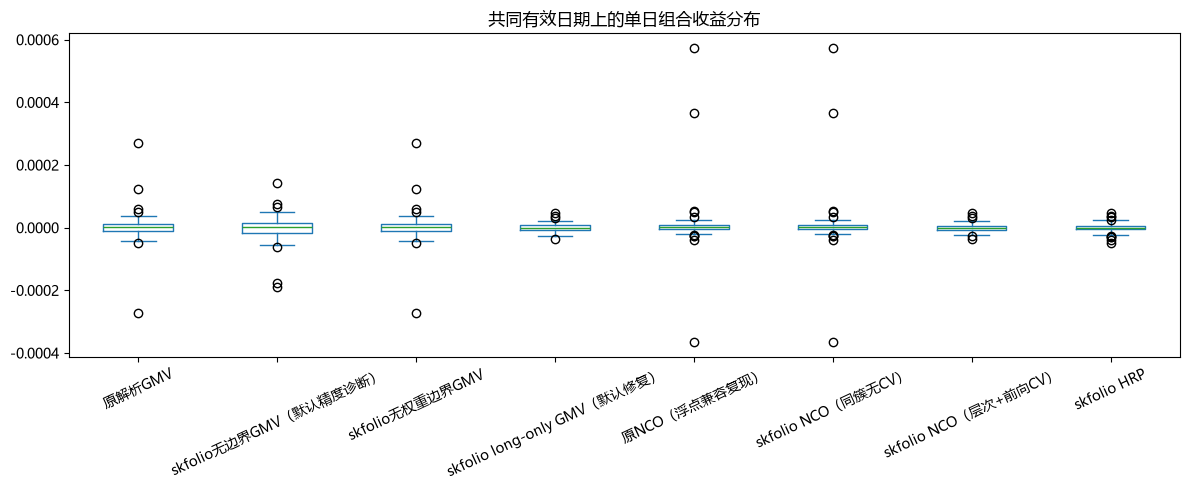

没有绘制跨缺失日期的伪连续净值，也未把缺失日期收益当作零。


In [4]:
rows, test_series = [], {}
for name, w in weights.items():
    train_r, test_r = X_train.to_numpy() @ w, X_test.to_numpy() @ w
    test_series[name] = test_r
    gross = np.abs(w).sum()
    rows.append({'模型': name, '训练单日方差': np.var(train_r, ddof=1),
                 '测试单日均值': test_r.mean(), '测试单日波动': test_r.std(ddof=1),
                 '测试非年化夏普': test_r.mean()/test_r.std(ddof=1) if test_r.std(ddof=1) else np.nan,
                 '最大绝对权重': np.abs(w).max(), '总敞口': gross,
                 '绝对权重集中度': np.sum((np.abs(w)/gross)**2), '负权重数': np.sum(w < -1e-7),
                 '拟合耗时秒（不含共用聚类）': run_times[name]})
display(pd.DataFrame(rows).set_index('模型'))
display(pd.Series(failures, name='失败原因（未替换）'))
weight_table = pd.DataFrame(weights, index=assets)
display(weight_table)
if test_series:
    test_returns = pd.DataFrame(test_series, index=X_test.index)
    test_returns.plot.box(rot=25, title='共同有效日期上的单日组合收益分布', figsize=(12, 5))
    plt.tight_layout(); plt.show()
    print('没有绘制跨缺失日期的伪连续净值，也未把缺失日期收益当作零。')
assert weights, '没有任何模型成功；请查看失败记录'

## 结论阅读
同一簇、协方差和约束下比较实现误差；层次聚类+前向CV+long-only是不同模型，不要求权重一致。
488只基金存在相关与病态问题，求解器近似解与矩阵求逆的差异需要结合风险和残差解释。
这里的固定权重日收益计算未包含成本、交易时点、停牌执行和复权核实，不能称为可交易绩效。